In [10]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

Подключены pandas и numpy для работы с данными, а из sklearn — инструменты для разделения выборки (train_test_split), построения пайплайнов предобработки (Pipeline, ColumnTransformer, SimpleImputer, StandardScaler, OneHotEncoder), подбора гиперпараметров через кросс-валидацию (GridSearchCV, StratifiedKFold), обучения модели k-ближайших соседей (KNeighborsClassifier) и оценки её качества (confusion_matrix, classification_report, roc_auc_score).

## Загрузка и очистка данных

In [11]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
class_counts = df["Churn"].value_counts(normalize=True) * 100
print(f'Баланс классов:\n (Клиенты остались): {class_counts["No"]:.1f}%\n (Клиенты ушли): {class_counts["Yes"]:.1f}%\n')

X = df.drop(["Churn", "customerID"], axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X.columns)

Баланс классов:
 (Клиенты остались): 73.5%
 (Клиенты ушли): 26.5%

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='str')


Проверили баланс классов — большинство клиентов (около 73%) остаются, а уходят примерно 27%. Удалили из признаков ненужный столбец customerID

## Настройка пайплайна 

In [12]:
numeric_features = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

categorical_features = ['gender', 'Partner', 'Dependents', 'PhoneService', 
                        'MultipleLines', 'InternetService', 'OnlineSecurity', 
                        'OnlineBackup', 'DeviceProtection', 'TechSupport', 
                        'StreamingTV', 'StreamingMovies', 'Contract', 
                        'PaperlessBilling', 'PaymentMethod']

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), 
           ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")), 
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

clf_pipline = Pipeline(
    steps=[("preprocessor", preprocessor), 
           ("classifier", KNeighborsClassifier())]
)

param_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights": ["uniform", "distance"],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=clf_pipline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print(f'\nЛучшие параметры алгоритма; {grid_search.best_params_}')




Лучшие параметры алгоритма; {'classifier__n_neighbors': 9, 'classifier__weights': 'uniform'}


Пайплайн, который автоматически обрабатывает пропуски, масштабирует числовые признаки и кодирует категориальные. 

## Оценка качества модели

In [13]:
y_pred = best_model.predict(X_test)

y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- Матрица ошибок ---")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно отрицательные (TN - клиент остался, модель верно предсказала) {conf_matrix[0][0]}")
print(f"Ложноположительные (FP - клиент остался, модель ошибочно предсказала уход) {conf_matrix[0][1]}")
print(f"Ложноотрицательные (FN - клиент ушёл, модель ошибочно предсказала, что останется) {conf_matrix[1][0]}")
print(f"Истинно полжительные (TP - клиент ушёл, модель верно предсказала) {conf_matrix[1][1]}")

print("--- Отчет по метрикам ---")
print(classification_report(y_test, y_pred, target_names=["Клиент остался (0)", "Клиент ушёл (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")

--- Матрица ошибок ---
Истинно отрицательные (TN - клиент остался, модель верно предсказала) 880
Ложноположительные (FP - клиент остался, модель ошибочно предсказала уход) 155
Ложноотрицательные (FN - клиент ушёл, модель ошибочно предсказала, что останется) 155
Истинно полжительные (TP - клиент ушёл, модель верно предсказала) 219
--- Отчет по метрикам ---
                    precision    recall  f1-score   support

Клиент остался (0)       0.85      0.85      0.85      1035
   Клиент ушёл (1)       0.59      0.59      0.59       374

          accuracy                           0.78      1409
         macro avg       0.72      0.72      0.72      1409
      weighted avg       0.78      0.78      0.78      1409

Площадь под кривой ROC-AUC: 0.8132


Модель показала общую точность около 78% (accuracy = 0.78), при этом она очень хорошо определяет лояльных клиентов с показателем 0.85. Для класса ушедших метрики скромнее и составляют примерно 0.59, что вполне нормально для таких данных. Значение ROC-AUC на уровне 0.81 подтверждает, что модель в целом надежно разделяет эти группы и дает качественный прогноз

In [14]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_error

## Подбор параметров 

In [15]:
df_reg = df.dropna(subset=['TotalCharges']).copy()
X_reg = df_reg[["SeniorCitizen", "tenure", "MonthlyCharges"]]
y_reg = df_reg["TotalCharges"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_pipeline = Pipeline(
    [("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())]
)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "knn_reg__n_neighbors": np.arange(3,30),
    "knn_reg__weights": ["uniform", "distance"]
}
random_search = RandomizedSearchCV(
    estimator=reg_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_r, y_train_r)
best_reg = random_search.best_estimator_
print(f"Лучшие параметры алгоритма: {random_search.best_params_}")

Лучшие параметры алгоритма: {'knn_reg__weights': 'distance', 'knn_reg__n_neighbors': np.int64(12)}


Пайплайн для предсказания итоговой суммы платежей клиента с помощью KNN-регрессии.

## Оценка качества регрессионной модели

In [16]:
y_pred_r = best_reg.predict(X_test_r)
def smape(y_test, y_pred):
    return 100* np.mean(
        2 * np.abs(y_pred-y_test)/(np.abs(y_test)+np.abs(y_pred))
    )
mse = mean_absolute_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape(y_test_r, y_pred_r)

print("--- Отчет по метрикам регрессии ---")
print(f"MSE (квадратные $) {mse:.0f}")
print(f"RMSE ($) {rmse:.0f}")
print(f"MAE (Средняя ошибка) {mae:.2f}")
print(f"SMAPE (ошибка в %) {smape_value:.2f}%")

--- Отчет по метрикам регрессии ---
MSE (квадратные $) 56
RMSE ($) 8
MAE (Средняя ошибка) 56.37
SMAPE (ошибка в %) 4.43%


Модель предсказывает общие затраты клиентов с небольшой ошибкой: в среднем она ошибается примерно на 56.37 долларов (MAE), а в процентах это всего     4.43% (SMAPE). Значение RMSE равно 8 долларам, что говорит о том, что больших выбросов в прогнозах почти нет. В целом модель работает достаточно точно для задачи предсказания суммы платежей.

## Визуальная оценка качества регрессионной модели

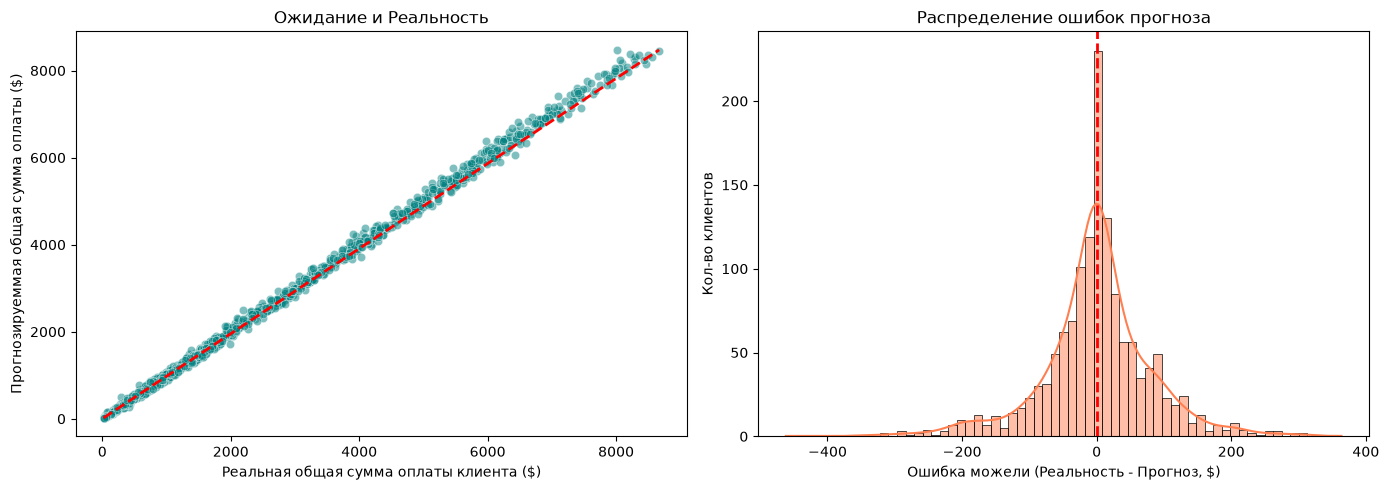

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1,2,figsize=(14,5))

sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color='teal', ax=axes[0])
axes[0].plot(
    [y_test_r.min(), y_test_r.max()], [y_pred_r.min(), y_pred_r.max()], 'r--', lw=2
)
axes[0].set_title("Ожидание и Реальность")
axes[0].set_xlabel("Реальная общая сумма оплаты клиента ($)")
axes[0].set_ylabel("Прогнозируеммая общая сумма оплаты ($)")

residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle="--", lw=2) # Линия нулевой ошибки
axes[1].set_title("Распределение ошибок прогноза")
axes[1].set_xlabel("Ошибка можели (Реальность - Прогноз, $)")
axes[1].set_ylabel("Кол-во клиентов")

plt.tight_layout()
plt.show()

На первом графике точки практически сливаются с красной линией идеального совпадения, что показывает очень высокую точность предсказания общих затрат клиента. На втором графике видно, что большинство ошибок сосредоточено около нуля с симметричным распределением, значит модель не имеет систематического смещения в сторону завышения или занижения. Обе диаграммы подтверждают, что регрессионная модель работает качественно и дает надежные прогнозы.